In [1]:
import pandas as pd

In [2]:
df = pd.read_excel('Athletes.xlsx')
df.head()
"""
Name (LAST First)
NOC
Discipline
"""

,Name,NOC,Discipline
0,AALERUD Katrine,Norway,Cycling Road
1,ABAD Nestor,Spain,Artistic Gymnastics
2,ABAGNALE Giovanni,Italy,Rowing
3,ABALDE Alberto,Spain,Basketball
4,ABALDE Tamara,Spain,Basketball


In [3]:
df.info()
"""
No null values are present in any column
"""

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11085 entries, 0 to 11084
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Name        11085 non-null  object
 1   NOC         11085 non-null  object
 2   Discipline  11085 non-null  object
dtypes: object(3)
memory usage: 259.9+ KB


In [4]:
df.describe()

,Name,NOC,Discipline
count,11085,11085,11085
unique,11062,206,46
top,WANG Yang,United States of America,Athletics
freq,2,615,2068


In [5]:
"""
Obtain list of disciplines to map to new column Parent_Discipline. 
This is to account for any athletes that compete in more than one event in a given Parent_Discipline.
"""
for i in df['Discipline'].sort_values().unique():
    print(i)

3x3 Basketball
Archery
Artistic Gymnastics
Artistic Swimming
Athletics
Badminton
Baseball/Softball
Basketball
Beach Volleyball
Boxing
Canoe Slalom
Canoe Sprint
Cycling BMX Freestyle
Cycling BMX Racing
Cycling Mountain Bike
Cycling Road
Cycling Track
Diving
Equestrian
Fencing
Football
Golf
Handball
Hockey
Judo
Karate
Marathon Swimming
Modern Pentathlon
Rhythmic Gymnastics
Rowing
Rugby Sevens
Sailing
Shooting
Skateboarding
Sport Climbing
Surfing
Swimming
Table Tennis
Taekwondo
Tennis
Trampoline Gymnastics
Triathlon
Volleyball
Water Polo
Weightlifting
Wrestling


In [6]:
"""
Create new column Parent_Discipline. 
This is to account for any athletes that compete in more than one Discipline in a given Parent_Discipline.
"""

df['Parent_Discipline'] = df['Discipline'].map({
    'Artistic Swimming': 'Aquatics',
    'Diving': 'Aquatics',
    'Marathon Swimming': 'Swimming',
    #'Swimming': 'Aquatics',
    'Water Polo': 'Aquatics',
    '3x3 Basketball': 'Basketball',
    'Canoe Slalom': 'Canoeing',
    'Canoe Sprint': 'Canoeing',
    'Cycling BMX Freestyle': 'Cycling',
    'Cycling BMX Racing': 'Cycling',
    'Cycling Mountain Bike': 'Cycling',
    'Cycling Road': 'Cycling',
    'Cycling Track': 'Cycling',
    'Artistic Gymnastics': 'Gymnastics',
    'Rhythmic Gymnastics': 'Gymnastics',
    'Trampoline Gymnastics': 'Gymnastics',
    'Beach Volleyball': 'Volleyball',
})
#df.head()

In [7]:
"""
If Parent_Discipline is null at this point, fill NaN with the Discipline
"""
df['Parent_Discipline'].fillna(df['Discipline'], inplace=True)
df.head()

,Name,NOC,Discipline,Parent_Discipline
0,AALERUD Katrine,Norway,Cycling Road,Cycling
1,ABAD Nestor,Spain,Artistic Gymnastics,Gymnastics
2,ABAGNALE Giovanni,Italy,Rowing,Rowing
3,ABALDE Alberto,Spain,Basketball,Basketball
4,ABALDE Tamara,Spain,Basketball,Basketball


In [8]:
"""Information about DF after Parent_Discipline column added"""
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11085 entries, 0 to 11084
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Name               11085 non-null  object
 1   NOC                11085 non-null  object
 2   Discipline         11085 non-null  object
 3   Parent_Discipline  11085 non-null  object
dtypes: object(4)
memory usage: 346.5+ KB


In [9]:
"""Information about DF after Parent_Discipline column added"""
df.describe()

,Name,NOC,Discipline,Parent_Discipline
count,11085,11085,11085,11085
unique,11062,206,46,34
top,WANG Yang,United States of America,Athletics,Athletics
freq,2,615,2068,2068


In [10]:
"""
In order to find the distinct number of athletes, create new DF with Name, NOC, and Parent_Discipline
"""
df_parent = df.loc[:, ['Name', 'NOC', 'Parent_Discipline']]

df_parent.drop_duplicates(inplace=True)
df_parent.head()

,Name,NOC,Parent_Discipline
0,AALERUD Katrine,Norway,Cycling
1,ABAD Nestor,Spain,Gymnastics
2,ABAGNALE Giovanni,Italy,Rowing
3,ABALDE Alberto,Spain,Basketball
4,ABALDE Tamara,Spain,Basketball


In [12]:
df_parent.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 11077 entries, 0 to 11084
Data columns (total 3 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Name               11077 non-null  object
 1   NOC                11077 non-null  object
 2   Parent_Discipline  11077 non-null  object
dtypes: object(3)
memory usage: 346.2+ KB


In [13]:
df_parent.describe()

,Name,NOC,Parent_Discipline
count,11077,11077,11077
unique,11062,206,34
top,SUN Jiajun,United States of America,Athletics
freq,2,614,2068


In [16]:
df_parent[(df_parent.Parent_Discipline=='Swimming') & (df_parent.Name=='van ROUWENDAAL Sharon')]

,Name,NOC,Parent_Discipline
10111,van ROUWENDAAL Sharon,Netherlands,Swimming


In [17]:
df[(df.Parent_Discipline=='Swimming') & (df.Name=='van ROUWENDAAL Sharon')]

,Name,NOC,Discipline,Parent_Discipline
10111,van ROUWENDAAL Sharon,Netherlands,Marathon Swimming,Swimming
10112,van ROUWENDAAL Sharon,Netherlands,Swimming,Swimming


In [18]:
"""
Find duplicated names and determine reason for them - keep all duplicated records
Do this for both DF and df_parent
"""
names_dupes_parent = df_parent[df_parent.duplicated(subset='Name', keep=False)==True]
names_dupes_parent.to_csv('names_dupes_parent.csv')
names_dupes_parent#.count()

"""
There are athletes with the same name in the same NOC that compete in different Parent_Disciplines.  Hence, different athletes.
There are athletes with the same name in different NOCs that compete in different Parent_Disciplines.  Hence, different athletes.
"""

,Name,NOC,Parent_Discipline
319,ALVAREZ Jorge,Cuba,Shooting
320,ALVAREZ Jorge,Honduras,Football
1703,CHEN Yang,People's Republic of China,Athletics
1704,CHEN Yang,People's Republic of China,Hockey
3664,HALL James,Great Britain,Gymnastics
3665,HALL James,United States of America,Shooting
4829,KIM Hyunsoo,Republic of Korea,Baseball/Softball
4830,KIM Hyunsoo,Republic of Korea,Rugby Sevens
5106,KOVACS Zsofia,Hungary,Gymnastics
5107,KOVACS Zsofia,Hungary,Triathlon


In [19]:
names_dupes = df[df.duplicated(subset='Name', keep=False)==True]
names_dupes.to_csv('names_dupes.csv')
names_dupes#.count()

"""
ALI Mohamed - not sure why there is a duplicate record
There are athletes that competed in multiple events within a parent discipline - hence same athlete (i.e. DYGERT Chloe)
"""

,Name,NOC,Discipline,Parent_Discipline
253,ALI Mohamed,Bahrain,Handball,Handball
254,ALI Mohamed,Bahrain,Handball,Handball
319,ALVAREZ Jorge,Cuba,Shooting,Shooting
320,ALVAREZ Jorge,Honduras,Football,Football
1703,CHEN Yang,People's Republic of China,Athletics,Athletics
1704,CHEN Yang,People's Republic of China,Hockey,Hockey
2551,DYGERT Chloe,United States of America,Cycling Road,Cycling
2552,DYGERT Chloe,United States of America,Cycling Track,Cycling
3128,GANNA Filippo,Italy,Cycling Road,Cycling
3129,GANNA Filippo,Italy,Cycling Track,Cycling


In [20]:
"""
Check if there are duplicates across all data (df and df_parent)
"""
df_parent[df_parent.duplicated(keep=False)==True]

,Name,NOC,Parent_Discipline


In [21]:
df[df.duplicated(keep=False)==True]

,Name,NOC,Discipline,Parent_Discipline
253,ALI Mohamed,Bahrain,Handball,Handball
254,ALI Mohamed,Bahrain,Handball,Handball


In [25]:
"""
Find distinct athletes in each NOC
Method 1 - simple groupby
"""
df_parent_noc = df_parent.loc[:, ['Name', 'NOC']].groupby('NOC').count().sort_values(by='Name', ascending=False).head(10)
df_parent_noc.drop_duplicates(inplace=True)
df_parent_noc

,Name
NOC,
United States of America,614
Japan,586
Australia,470
People's Republic of China,401
Germany,399
France,377
Canada,368
Great Britain,366
Italy,354


In [36]:
"""
Method 2 - use transform statement to create a new column called NOC_Athlete_Count
"""
df_parent['NOC_Athlete_Count'] = df_parent.groupby(['NOC'])['Name'].transform('count')
#df_parent[df_parent.NOC=='United States of America']
df_parent[(df_parent.NOC=='United States of America') & (df_parent.Parent_Discipline=='Swimming')]
#df_parent[df_parent.Name=='van ROUWENDAAL Sharon']

,Name,NOC,Parent_Discipline,NOC_Athlete_Count
380,ANDERSON Haley,United States of America,Swimming,614
405,ANDREW Michael,United States of America,Swimming,614
466,APPLE Zach,United States of America,Swimming,614
521,ARMSTRONG Joseph,United States of America,Swimming,614
649,BACON Phoebe,United States of America,Swimming,614
928,BENTZ Gunnar,United States of America,Swimming,614
1267,BRINEGAR Michael,United States of America,Swimming,614
1295,BROWN Erika,United States of America,Swimming,614
2041,CURZAN Claire,United States of America,Swimming,614
2194,de LOOF Catie,United States of America,Swimming,614


In [38]:
df_parent_noc2 = df_parent.loc[:, ['NOC', 'NOC_Athlete_Count']].drop_duplicates()
df_parent_noc2.sort_values(by='NOC_Athlete_Count', ascending=False)

,NOC,NOC_Athlete_Count
12,United States of America,614
43,Japan,586
11,Australia,470
156,People's Republic of China,401
34,Germany,399
...,...,...
3202,United Republic of Tanzania,2
1853,Saint Kitts and Nevis,2
3069,Marshall Islands,2
2031,Vanuatu,2


<AxesSubplot:xlabel='NOC'>

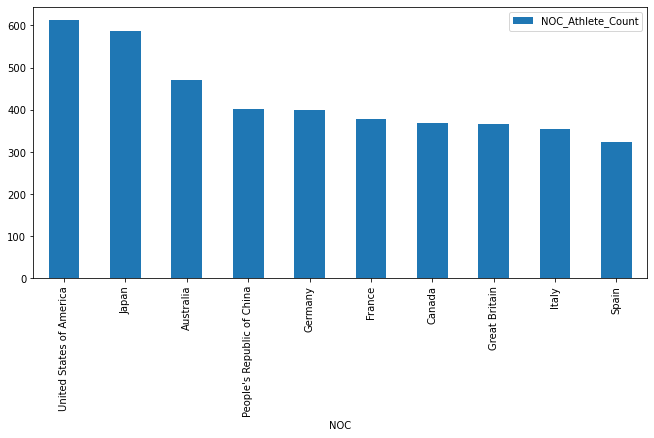

In [41]:
df_parent_noc2.sort_values(by='NOC_Athlete_Count', ascending=False).head(10).plot.bar(x='NOC', y='NOC_Athlete_Count', figsize=(11,5))

In [42]:
"""
Find number of athletes competing in each discipline.  
These do not take into account *distinct* athletes. I.e. marathon swimmers also were swimmers
"""
df.loc[:, ['Parent_Discipline', 'Discipline', 'Name']].groupby(['Parent_Discipline', 'Discipline']).count()

Name
Parent_Discipline Discipline                 
Aquatics          Artistic Swimming        98
                  Diving                  133
                  Water Polo              269
Archery           Archery                 122
Athletics         Athletics              2068
Badminton         Badminton               164
Baseball/Softball Baseball/Softball       220
Basketball        3x3 Basketball           62
                  Basketball              280
Boxing            Boxing                  270
Canoeing          Canoe Slalom             78
                  Canoe Sprint            236
Cycling           Cycling BMX Freestyle    19
                  Cycling BMX Racing       43
                  Cycling Mountain Bike    74
                  Cycling Road            190
                  Cycling Track           208
Equestrian        Equestrian              237
Fencing           Fencing                 249
Football          Football                567
Golf              Golf                    115
Gymnastics        Artistic Gymnastics     187
                  Rhythmic Gymnastics      95
                  Trampoline Gymnastics    31
Handball          Handball                343
Hockey            Hockey                  406
Judo              Judo                    373
Karate            Karate                   77
Modern Pentathlon Modern Pentathlon        69
Rowing            Rowing                  496
Rugby Sevens      Rugby Sevens            283
Sailing           Sailing                 336
Shooting          Shooting                342
Skateboarding     Skateboarding            77
Sport Climbing    Sport Climbing           37
Surfing           Surfing                  38
Swimming          Marathon Swimming        49
                  Swimming                743
Table Tennis      Table Tennis            164
Taekwondo         Taekwondo               123
Tennis            Tennis                  178
Triathlon         Triathlon               106
Volleyball        Beach Volleyball         90
                  Volleyball              274
Weightlifting     Weightlifting           187
Wrestling         Wrestling               279

In [44]:
df_parent.loc[:, ['Parent_Discipline', 'Name']].groupby('Parent_Discipline').count()
#these take into account *distinct* athlete

,Name
Parent_Discipline,
Aquatics,500
Archery,122
Athletics,2068
Badminton,164
Baseball/Softball,220
Basketball,342
Boxing,270
Canoeing,314
Cycling,530


In [45]:
df_parent['Parent_Disc_Athlete_Count'] = df_parent.groupby(['Parent_Discipline'])['Name'].transform('count')
df_parent.head()

,Name,NOC,Parent_Discipline,NOC_Athlete_Count,Parent_Disc_Athlete_Count
0,AALERUD Katrine,Norway,Cycling,92,530
1,ABAD Nestor,Spain,Gymnastics,324,313
2,ABAGNALE Giovanni,Italy,Rowing,354,496
3,ABALDE Alberto,Spain,Basketball,324,342
4,ABALDE Tamara,Spain,Basketball,324,342


<AxesSubplot:xlabel='Parent_Discipline'>

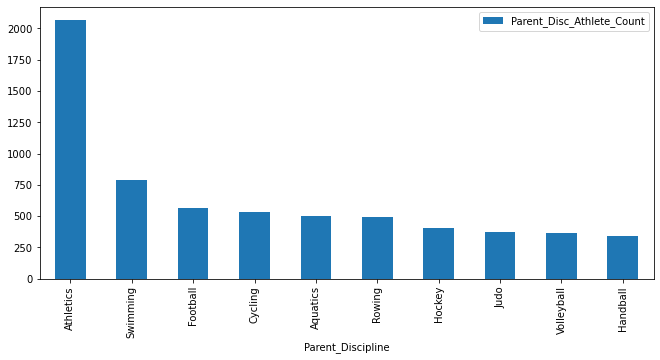

In [47]:
df_parent_ath = df_parent.loc[:, ['Parent_Discipline', 'Parent_Disc_Athlete_Count']].drop_duplicates()
df_parent_ath.sort_values(by='Parent_Disc_Athlete_Count', ascending=False).head(10).plot.bar(x='Parent_Discipline', y='Parent_Disc_Athlete_Count', figsize=(11,5))

In [24]:
aquatics = df[df.Parent_Discipline=='Swimming']#.duplicated(subset='Name', keep=False)]
aquatics[aquatics.duplicated(subset='Name', keep=False)]

,Name,NOC,Discipline,Parent_Discipline
7395,PALTRINIERI Gregorio,Italy,Marathon Swimming,Swimming
7396,PALTRINIERI Gregorio,Italy,Swimming,Swimming
10111,van ROUWENDAAL Sharon,Netherlands,Marathon Swimming,Swimming
10112,van ROUWENDAAL Sharon,Netherlands,Swimming,Swimming
10505,WELLBROCK Florian,Germany,Marathon Swimming,Swimming
10506,WELLBROCK Florian,Germany,Swimming,Swimming


In [25]:
aquatics_parent = df_parent[df_parent.Parent_Discipline=='Swimming']
aquatics_parent[aquatics_parent.duplicated(subset='Name', keep=False)]

,Name,NOC,Parent_Discipline


In [51]:
df_parent['Name'].count()

11077

<AxesSubplot:xlabel='Parent_Discipline'>

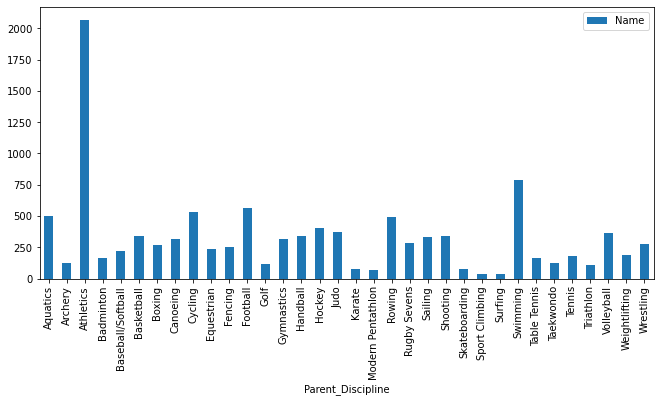

In [27]:
athletes_parent_discipline = df_parent.loc[:, ['Parent_Discipline', 'Name']].groupby('Parent_Discipline').count()
athletes_parent_discipline.plot.bar(figsize=(11,5))

In [28]:
athletes_parent_discipline.describe()

,Name
count,34.000000
mean,325.794118
std,351.502988
min,37.000000
25%,133.250000
50%,274.500000
75%,358.500000
max,2068.000000
